#  Flight Delay & Cancellation Analysis
## Week 4 – Exploratory Data Analysis (EDA)

### Course: 24ADI204 – Data Science and Visualization
### Project Type: Hack-A-BIT (Visual Storytelling Challenge)
---
### Objective of Week 4
To uncover underlying patterns, correlations, and anomalies in the cleaned flight dataset using visual storytelling.

**Key Analytical Checkpoints:**
1. **Univariate Analysis:** Understanding the distribution of single variables (Arrival/Departure Delays).
2. **Bivariate Analysis:** Mapping the direct relationship between departure performance and arrival outcomes.
3. **Categorical Analysis:** Comparing operational efficiency across Top Airlines.
4. **Temporal/Seasonal Analysis:** Evaluating the impact of seasonal weather patterns on flight disruptions.
5. **Correlation Matrix:** Identifying the mathematical relationships between various delay causes.

In [3]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

sns.set(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)


# The cleaned dataset generated after missing value handling and outlier detection (Week 3) is used for analysis.


 # Initial Data Check

In [4]:
data = pd.read_csv("flight_delay_cleaned.csv")
data.head()


,YEAR,MONTH,DAY_OF_MONTH,OP_UNIQUE_CARRIER,ORIGIN_AIRPORT_ID,ORIGIN_AIRPORT_SEQ_ID,ORIGIN_CITY_MARKET_ID,ORIGIN,ORIGIN_CITY_NAME,DEST_AIRPORT_ID,...,ARR_TIME,ARR_DELAY,CANCELLED,DIVERTED,CARRIER_DELAY,WEATHER_DELAY,NAS_DELAY,SECURITY_DELAY,LATE_AIRCRAFT_DELAY,DelayCategory
0,2024,1,1,9E,10135,1013506,30135,ABE,"Allentown/Bethlehem/Easton, PA",10397,...,757.0,-35.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,On-Time/Early
1,2024,1,1,9E,10135,1013506,30135,ABE,"Allentown/Bethlehem/Easton, PA",10397,...,1437.0,-13.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,On-Time/Early
2,2024,1,1,9E,10185,1018502,30185,AEX,"Alexandria, LA",10397,...,821.0,-29.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,On-Time/Early
3,2024,1,1,9E,10185,1018502,30185,AEX,"Alexandria, LA",10397,...,1851.0,-26.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,On-Time/Early
4,2024,1,1,9E,10208,1020803,30208,AGS,"Augusta, GA",10397,...,1947.0,-23.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,On-Time/Early


 # Dataset Structure

###  1. Data Verification (Post-Cleaning Audit)
Before diving into visual analysis, we verify that the dataset reflects our Week 3 Data Engineering efforts.
* Expected Outcome: `CANCELLED` flights should be 0 (as they were removed), and extreme delay maximums should be capped at 1440 minutes.

In [5]:
data.info()


<class 'pandas.DataFrame'>
RangeIndex: 1747822 entries, 0 to 1747821
Data columns (total 27 columns):
 #   Column                 Dtype  
---  ------                 -----  
 0   YEAR                   int64  
 1   MONTH                  int64  
 2   DAY_OF_MONTH           int64  
 3   OP_UNIQUE_CARRIER      str    
 4   ORIGIN_AIRPORT_ID      int64  
 5   ORIGIN_AIRPORT_SEQ_ID  int64  
 6   ORIGIN_CITY_MARKET_ID  int64  
 7   ORIGIN                 str    
 8   ORIGIN_CITY_NAME       str    
 9   DEST_AIRPORT_ID        int64  
 10  DEST_AIRPORT_SEQ_ID    int64  
 11  DEST_CITY_MARKET_ID    int64  
 12  DEST                   str    
 13  CRS_DEP_TIME           str    
 14  DEP_TIME               float64
 15  DEP_DELAY              float64
 16  CRS_ARR_TIME           str    
 17  ARR_TIME               float64
 18  ARR_DELAY              float64
 19  CANCELLED              float64
 20  DIVERTED               float64
 21  CARRIER_DELAY          float64
 22  WEATHER_DELAY          float6

# Statistical Summary

In [6]:
data.describe()


,YEAR,MONTH,DAY_OF_MONTH,ORIGIN_AIRPORT_ID,ORIGIN_AIRPORT_SEQ_ID,ORIGIN_CITY_MARKET_ID,DEST_AIRPORT_ID,DEST_AIRPORT_SEQ_ID,DEST_CITY_MARKET_ID,DEP_TIME,DEP_DELAY,ARR_TIME,ARR_DELAY,CANCELLED,DIVERTED,CARRIER_DELAY,WEATHER_DELAY,NAS_DELAY,SECURITY_DELAY,LATE_AIRCRAFT_DELAY
count,1747822.0,1.747822e+06,1.747822e+06,1.747822e+06,1.747822e+06,1.747822e+06,1.747822e+06,1.747822e+06,1.747822e+06,1.747822e+06,1.747822e+06,1.747822e+06,1.747822e+06,1747822.0,1747822.0,1.747822e+06,1.747822e+06,1.747822e+06,1.747822e+06,1.747822e+06
mean,2024.0,6.240954e+00,1.598958e+01,1.264525e+04,1.264529e+06,3.173505e+04,1.264578e+04,1.264582e+06,3.173557e+04,1.330450e+03,1.433428e+01,1.459890e+03,8.991615e+00,0.0,0.0,6.024398e+00,1.037484e+00,2.779290e+00,2.994527e-02,6.747651e+00
std,0.0,3.657641e+00,8.949267e+00,1.532606e+03,1.532604e+05,1.323885e+03,1.532763e+03,1.532761e+05,1.324141e+03,5.095775e+02,5.872193e+01,5.463739e+02,6.098878e+01,0.0,0.0,3.840437e+01,1.714598e+01,1.475774e+01,1.654477e+00,3.292781e+01
min,2024.0,1.000000e+00,1.000000e+00,1.013500e+04,1.013506e+06,3.007000e+04,1.013500e+04,1.013506e+06,3.007000e+04,1.000000e+00,-6.600000e+01,1.000000e+00,-9.100000e+01,0.0,0.0,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
25%,2024.0,1.000000e+00,8.000000e+00,1.129200e+04,1.129202e+06,3.061500e+04,1.129200e+04,1.129202e+06,3.061500e+04,9.080000e+02,-6.000000e+00,1.044000e+03,-1.500000e+01,0.0,0.0,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
50%,2024.0,7.000000e+00,1.600000e+01,1.288900e+04,1.288904e+06,3.145300e+04,1.288900e+04,1.288904e+06,3.145300e+04,1.324000e+03,-2.000000e+00,1.502000e+03,-6.000000e+00,0.0,0.0,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
75%,2024.0,1.000000e+01,2.400000e+01,1.402700e+04,1.402702e+06,3.246700e+04,1.405700e+04,1.405702e+06,3.246700e+04,1.745000e+03,1.100000e+01,1.918000e+03,1.100000e+01,0.0,0.0,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
max,2024.0,1.000000e+01,3.100000e+01,1.686900e+04,1.686902e+06,3.599100e+04,1.686900e+04,1.686902e+06,3.599100e+04,2.400000e+03,1.440000e+03,2.400000e+03,1.440000e+03,0.0,0.0,1.440000e+03,1.440000e+03,1.431000e+03,1.005000e+03,1.440000e+03


# Arrival Delay Distribution

### 2. Univariate Analysis: Delay Distributions
**Goal:** To understand the frequency and spread of flight delays.
*Note: Because flight delays follow a heavy-tailed distribution (Power Law), we zoom in on the 0-300 minute range to clearly visualize the density curve.*

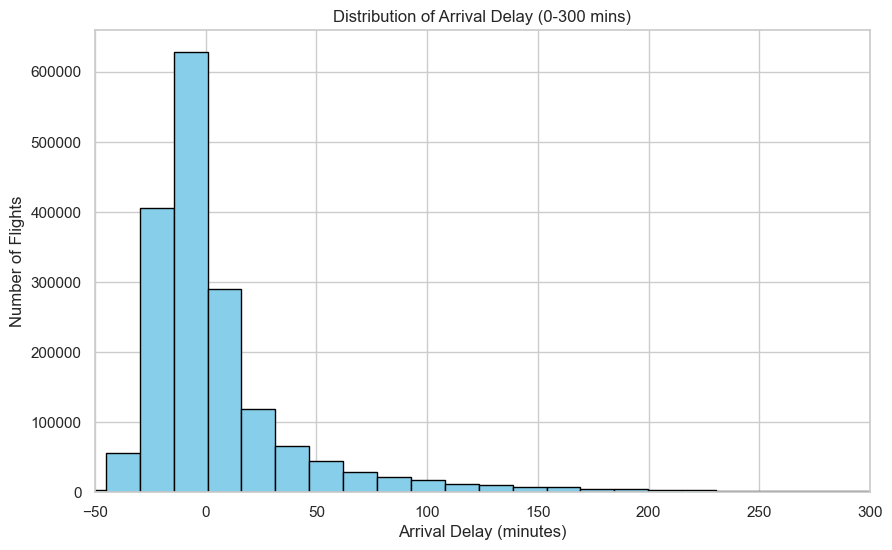

In [7]:
# Arrival Delay Distribution (Zoomed In)
plt.figure(figsize=(10, 6))
plt.hist(data["ARR_DELAY"], bins=100, color='skyblue', edgecolor='black')
plt.xlim(-50, 300) 
plt.xlabel("Arrival Delay (minutes)")
plt.ylabel("Number of Flights")
plt.title("Distribution of Arrival Delay (0-300 mins)")
plt.show()


# Departure Delay Distribution

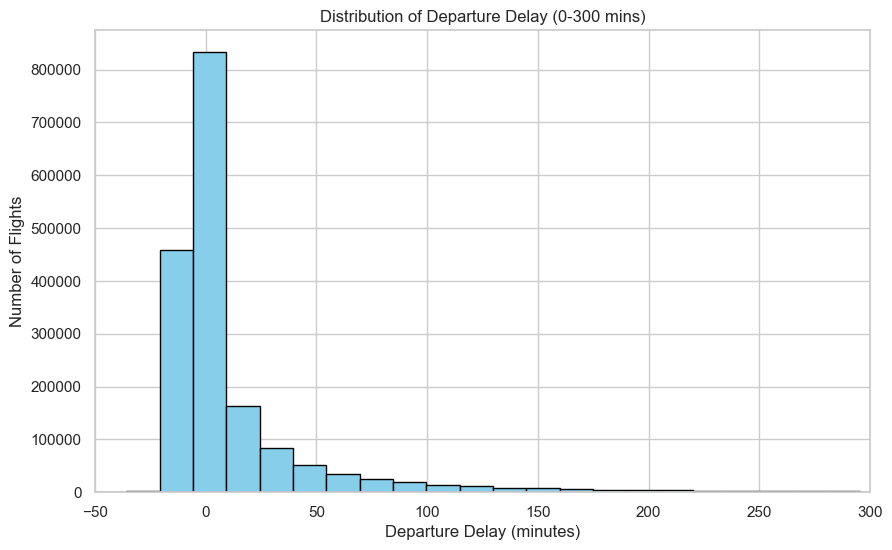

In [8]:

# Arrival Delay Distribution (Zoomed In)
plt.figure(figsize=(10, 6))
plt.hist(data["DEP_DELAY"], bins=100, color='skyblue', edgecolor='black')
plt.xlim(-50, 300) # Zoom in to ignore extreme outliers for the visual
plt.xlabel("Departure Delay (minutes)")
plt.ylabel("Number of Flights")
plt.title("Distribution of Departure Delay (0-300 mins)")
plt.show()

# Departure Delay vs Arrival Delay

### 3. Bivariate Analysis: Departure vs. Arrival Delays
**Goal:** To visualize how heavily Arrival Delays depend on Departure Delays.
*Technique:* With over 1.6 million records, standard scatter plots suffer from extreme overplotting (creating a solid block of color). We apply a heavy transparency layer (`alpha=0.05`) to create a density map. The red dashed line represents a 1:1 ratio.

**Insight:** Flights below the red line indicate instances where pilots successfully "made up time" in the air despite a late departure.

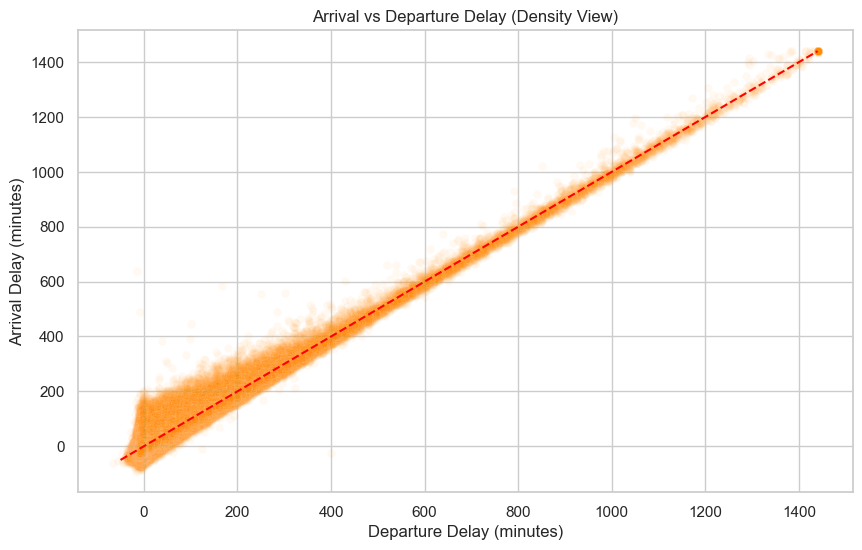

In [10]:
plt.figure(figsize=(10, 6))
# alpha=0.05 turns the scatter into a density map for Big Data
sns.scatterplot(x="DEP_DELAY", y="ARR_DELAY", data=data, alpha=0.05, color='darkorange')
plt.xlabel("Departure Delay (minutes)")
plt.ylabel("Arrival Delay (minutes)")
plt.title("Arrival vs Departure Delay (Density View)")
plt.plot([-50, 1440], [-50, 1440], color='red', linestyle='--')
plt.show()


In [11]:
data.columns

Index(['YEAR', 'MONTH', 'DAY_OF_MONTH', 'OP_UNIQUE_CARRIER',
       'ORIGIN_AIRPORT_ID', 'ORIGIN_AIRPORT_SEQ_ID', 'ORIGIN_CITY_MARKET_ID',
       'ORIGIN', 'ORIGIN_CITY_NAME', 'DEST_AIRPORT_ID', 'DEST_AIRPORT_SEQ_ID',
       'DEST_CITY_MARKET_ID', 'DEST', 'CRS_DEP_TIME', 'DEP_TIME', 'DEP_DELAY',
       'CRS_ARR_TIME', 'ARR_TIME', 'ARR_DELAY', 'CANCELLED', 'DIVERTED',
       'CARRIER_DELAY', 'WEATHER_DELAY', 'NAS_DELAY', 'SECURITY_DELAY',
       'LATE_AIRCRAFT_DELAY', 'DelayCategory'],
      dtype='str')

# Airline vs Arrival Delay

### 4. Operational Analysis: Top 10 Airlines Performance
**Goal:** To compare the delay distributions among the highest-volume carriers.
By filtering for the Top 10 airlines, we can evaluate which carriers have the tightest operational variance (smaller boxes) versus those prone to massive delays (long upper whiskers).

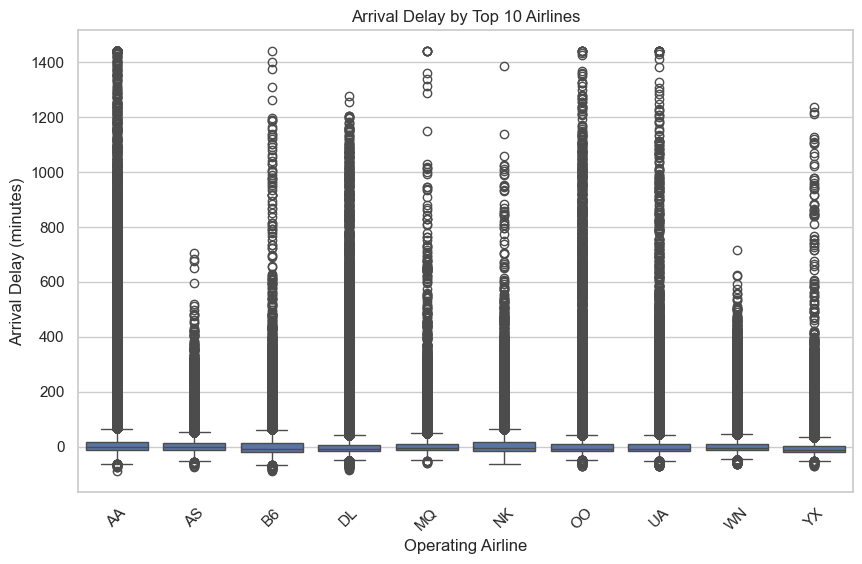

In [12]:
top_airlines = data["OP_UNIQUE_CARRIER"].value_counts().head(10).index

filtered_data = data[data["OP_UNIQUE_CARRIER"].isin(top_airlines)]

sns.boxplot(
    x="OP_UNIQUE_CARRIER",
    y="ARR_DELAY",
    data=filtered_data
)

plt.xlabel("Operating Airline")
plt.ylabel("Arrival Delay (minutes)")
plt.title("Arrival Delay by Top 10 Airlines")
plt.xticks(rotation=45)
plt.show()


# Weather Delay Impact

### Bivariate Analysis: Weather Delay vs. Total Arrival Delay
**Goal:** To isolate "Weather" as a specific disruption metric and analyze how heavily it dictates the final arrival time.
*Technique:* We use a scatterplot with high transparency (`alpha=0.1`) because both variables are continuous. 

**Insight:** The visualization reveals a stark pattern: the vast majority of flights have 0 minutes of weather delay (the thick horizontal line at the bottom). However, when a weather delay *does* occur, it scales linearly with the total arrival delay. This indicates that weather, while a relatively rare primary cause of delay, is extremely severe when it happens and is almost never "made up for" in the air.

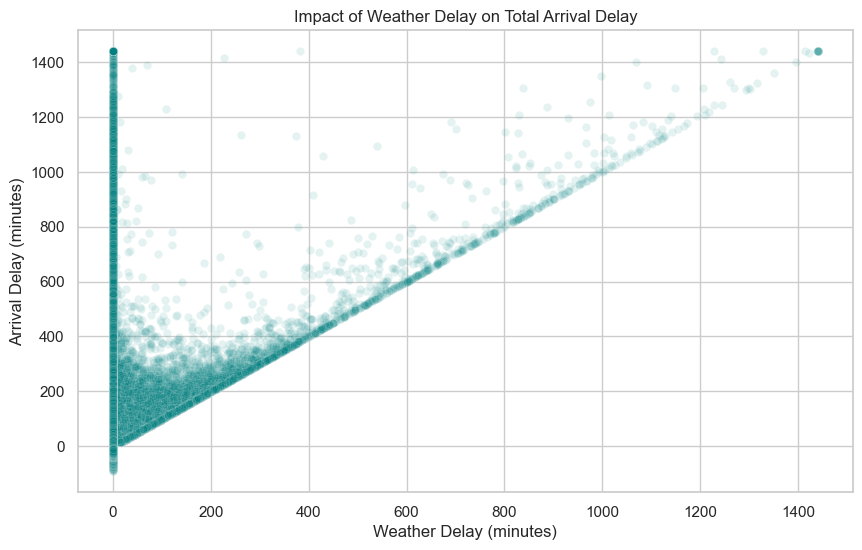

In [13]:
plt.figure(figsize=(10, 6))
# Changed from boxplot to scatterplot because both variables are continuous
sns.scatterplot(x="WEATHER_DELAY", y="ARR_DELAY", data=data, alpha=0.1, color='teal')
plt.xlabel("Weather Delay (minutes)")
plt.ylabel("Arrival Delay (minutes)")
plt.title("Impact of Weather Delay on Total Arrival Delay")
plt.show()

# Correlation Heatmap

### 6. Correlation Matrix: Delay Causes
**Goal:** To identify mathematical relationships between specific types of delays.
We isolate the core numerical delay metrics to generate a clean, readable heatmap. 

**Insight:** Strong positive correlations (approaching 1.0) indicate variables that move together. For example, `DEP_DELAY` and `ARR_DELAY` will show near-perfect correlation, while individual causes like `WEATHER_DELAY` act independently.

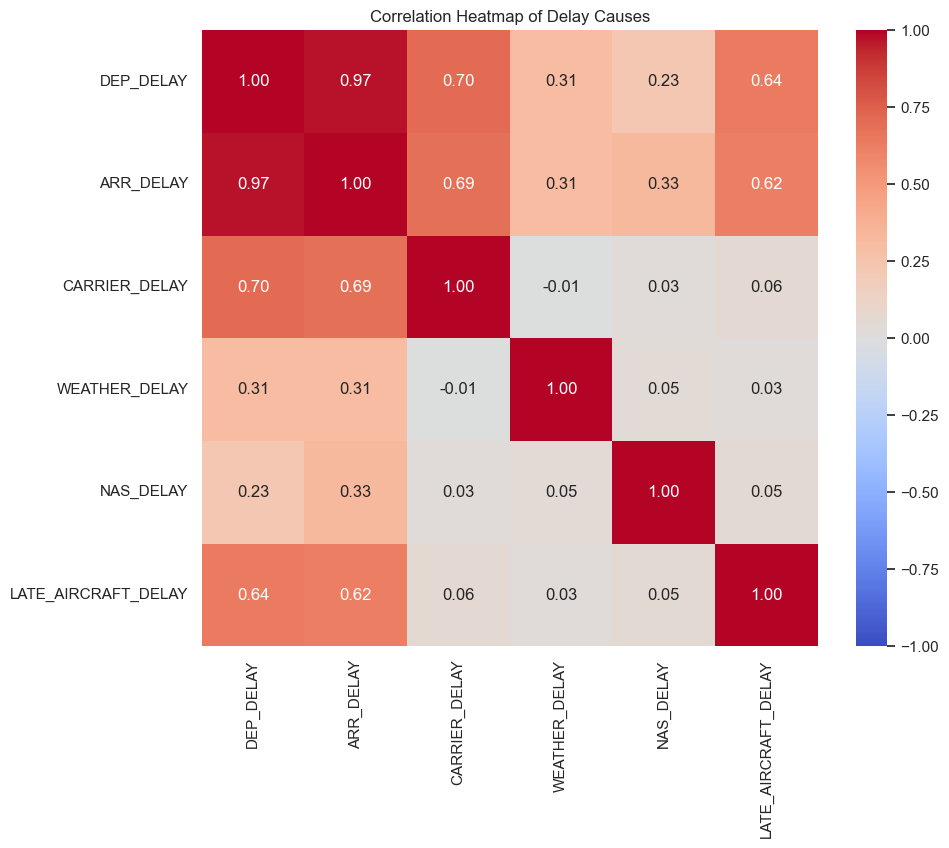

In [14]:
plt.figure(figsize=(10, 8))
# Filter to only the core delay metrics to make the heatmap readable
delay_features = ['DEP_DELAY', 'ARR_DELAY', 'CARRIER_DELAY', 
                  'WEATHER_DELAY', 'NAS_DELAY', 'LATE_AIRCRAFT_DELAY']

correlation_matrix = data[delay_features].corr()

sns.heatmap(correlation_matrix, annot=True, fmt=".2f", 
            cmap="coolwarm", vmin=-1, vmax=1, square=True)
plt.title("Correlation Heatmap of Delay Causes")
plt.show()

### 5. Feature Engineering: Temporal & Seasonal Grouping
**Goal:** To transition from granular data (individual months) to macro-level operational trends (seasons) to better understand the root causes of flight disruptions.

**Technique:** The raw dataset provides the `MONTH` as an integer (1-12). While useful, it doesn't tell a complete story about weather patterns or peak travel periods. We are engineering a new categorical feature called `SEASON` that groups these months into three distinct operational periods: **Winter**, **Summer**, and **Monsoon/Fall**. 

**Insight:** This newly engineered feature will allow us to evaluate whether severe delays are driven more by winter storms or summer vacation traffic volumes.

In [15]:

def get_season(month):
    if month in [11, 12, 1, 2]:
        return 'Winter'
    elif month in [3, 4, 5, 6]:
        return 'Summer'
    else: 
        return 'Monsoon/Fall'

data['SEASON'] = data['MONTH'].apply(get_season)

print(" 'SEASON' column created successfully!")

 'SEASON' column created successfully!


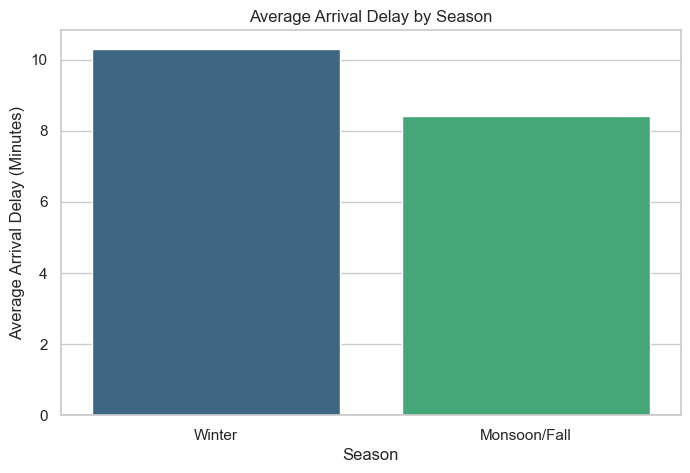

In [20]:
plt.figure(figsize=(8, 5))
# Added hue='SEASON' and legend=False to stop the warning
sns.barplot(x='SEASON', y='ARR_DELAY', data=data, 
            hue='SEASON', palette='viridis', legend=False, errorbar=None) 
plt.title("Average Arrival Delay by Season")
plt.xlabel("Season")
plt.ylabel("Average Arrival Delay (Minutes)")
plt.axhline(0, color='black', linewidth=1)
plt.show()

### Intrepretation
This stacked proportional chart shifts our interpretation from duration to causality. We can clearly see that while 'Weather' makes up a larger percentage of delays in the Winter, 'NAS Delay' (National Airspace System / Heavy Air Traffic) dominates the Summer months due to peak vacation travel volumes.

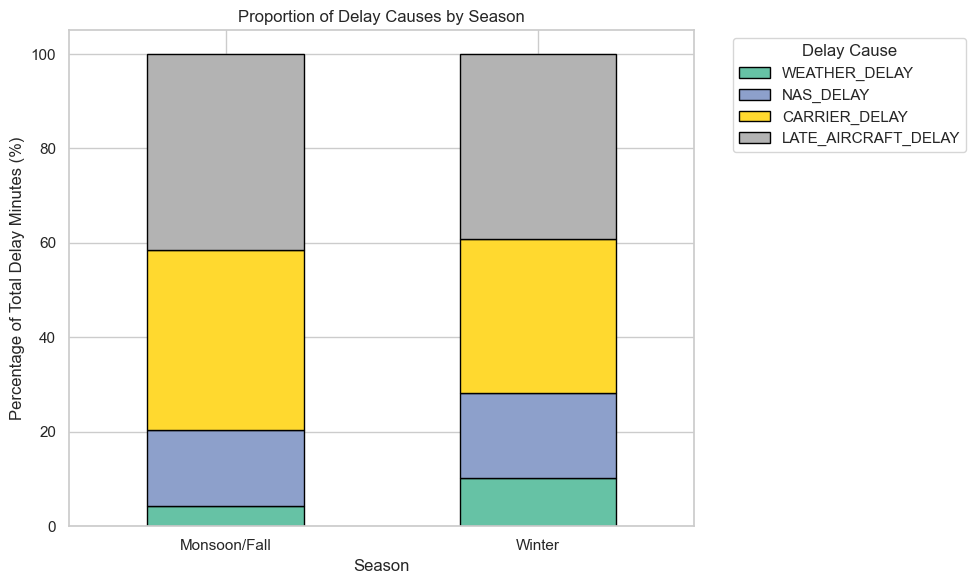

In [18]:

delay_causes = ['WEATHER_DELAY', 'NAS_DELAY', 'CARRIER_DELAY', 'LATE_AIRCRAFT_DELAY']
seasonal_causes = data.groupby('SEASON')[delay_causes].sum()

seasonal_causes_pct = seasonal_causes.div(seasonal_causes.sum(axis=1), axis=0) * 100

seasonal_causes_pct.plot(kind='bar', stacked=True, figsize=(10, 6), colormap='Set2', edgecolor='black')

plt.title("Proportion of Delay Causes by Season")
plt.xlabel("Season")
plt.ylabel("Percentage of Total Delay Minutes (%)")
plt.legend(title="Delay Cause", bbox_to_anchor=(1.05, 1), loc='upper left')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

### Intepretation
Rather than measuring average delay minutes (which can be skewed by extreme outliers), this visualization interprets the data through the lens of passenger risk. By defining a delay as >15 minutes (industry standard), we identify which season presents the highest probability of a disrupted itinerary.

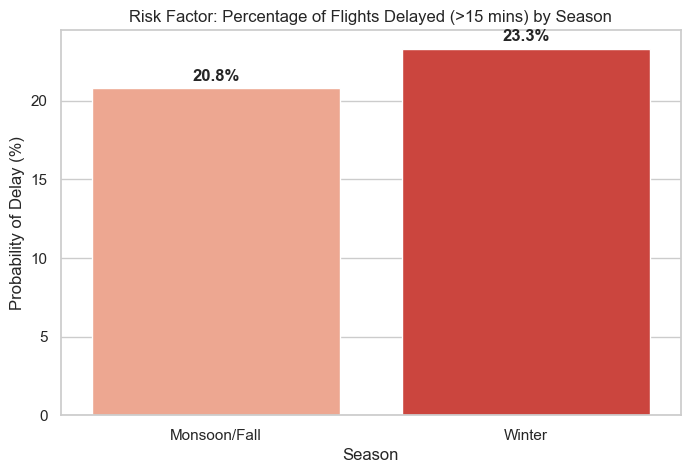

In [21]:
plt.figure(figsize=(8, 5))
# Added hue=risk_by_season.index and legend=False
sns.barplot(x=risk_by_season.index, y=risk_by_season.values, 
            hue=risk_by_season.index, palette='Reds', legend=False)

plt.title("Risk Factor: Percentage of Flights Delayed (>15 mins) by Season")
plt.xlabel("Season")
plt.ylabel("Probability of Delay (%)")

for i, val in enumerate(risk_by_season.values):
    plt.text(i, val + 0.5, f"{val:.1f}%", ha='center', fontweight='bold')

plt.show()